# Pergunta 2.2: qual modelo usar, e por quê?

> **Pergunta do case:** treine pelo menos um modelo de regressão. Explique sua escolha.

Um **modelo de regressão** aprende, com exemplos, uma regra que transforma as colunas de um criativo num número (aqui, a nota de 0 a 100).

| Passo | Pergunta |
|---|---|
| 1 | Quanto erra quem não usa modelo nenhum? (as referências mínimas) |
| 2 | Quais modelos testar, e o que cada um faz? |
| 3 | Como ajustar a Random Forest? |
| 4 | Como ajustar a rede neural? |
| 5 | A comparação final, no Modelo A e no B |
| 6 | Um modelo para todas as redes ou um por rede? |
| 7 | A escolha, e o modelo salvo para a Parte 3 |

Tudo usa só o **treino**, com a validação cruzada do notebook 2.1 (5 partes × 3 repetições = 15 provas, as mesmas para todos os modelos). O teste continua guardado.

## Passo 0: preparação

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

RAIZ = Path("../..")
sys.path.append(str(RAIZ))
from src.avaliacao import dobras, resumir, validar
from src.features import (ALVO, CATEGORIAS_A, COLUNAS_A, COLUNAS_B, NOVAS_A, NUMERICAS, NUMERICAS_B,
                          carregar_treino_teste, efeitos_em_pontos, montar_pipeline)

warnings.filterwarnings("ignore", category=UserWarning)  # avisos de convergência da rede neural
pd.set_option("display.width", 200)
AZUL, CINZA, CINZA_CLARO = "#2a78d6", "#52514e", "#b8b7b1"

treino, _ = carregar_treino_teste(RAIZ / "data/raw/klike_challenge_dataset.csv")  # o teste não é usado aqui
y = treino[ALVO]
cortes = dobras(treino)
CONJUNTOS = {"A": (COLUNAS_A, NUMERICAS), "B": (COLUNAS_B, NUMERICAS_B)}


def pipeline(modelo, conjunto, novas=NOVAS_A):
    colunas, numericas = CONJUNTOS[conjunto]
    return montar_pipeline(modelo, numericas, CATEGORIAS_A, novas)


def avaliar(modelo, conjunto, novas=NOVAS_A):
    colunas, _ = CONJUNTOS[conjunto]
    return validar(pipeline(modelo, conjunto, novas), treino[colunas], y, cortes)

## Passo 1: quanto erra quem não usa modelo nenhum?

Antes de qualquer modelo, duas **referências mínimas** (o `DummyRegressor` do scikit-learn). Um modelo só vale a pena se ganhar delas com folga.

- **Média geral:** chutar a mesma nota (a média do treino) para todo criativo.
- **Média da plataforma:** chutar a média da rede do criativo. Faço isso com uma regressão linear que só vê a plataforma: com uma coluna 0/1 por rede, a melhor reta é exatamente a média de cada rede.

In [2]:
referencias = {
    "média geral": validar(montar_pipeline(DummyRegressor(), [], ["platform"]), treino[["platform"]], y, cortes),
    "média da plataforma": validar(montar_pipeline(LinearRegression(), [], ["platform"]), treino[["platform"]], y, cortes),
}
pd.DataFrame({nome: resumir(r) for nome, r in referencias.items()}).T

,MAE,RMSE,R²
média geral,12.81 ± 0.97,15.84 ± 1.17,-0.01 ± 0.01
média da plataforma,12.72 ± 0.95,15.76 ± 1.10,0.00 ± 0.02


**A régua:** chutar a média erra **12,8 pontos** em média (R² perto de 0: não explica nada). Saber a plataforma quase não ajuda (12,7), porque a nota mediana é parecida nas três redes (Parte 1). Qualquer modelo precisa ficar bem abaixo de 12,8.

## Passo 2: quais modelos testar?

| Modelo | O que faz | Analogia |
|---|---|---|
| **Regressão linear** | soma um peso por coluna: nota = base + peso do gancho × (tem gancho) + ... Cada peso se lê "mantendo o resto igual" | uma receita: cada ingrediente soma um tanto ao sabor |
| **Random Forest** | centenas de **árvores de decisão** (sequências de perguntas sim/não, como "tem gancho?" → "é TikTok?"), cada uma treinada num sorteio dos dados; a previsão é a média delas. Pega curvas e combinações sem que eu precise criá-las | perguntar a 300 especialistas que viram casos diferentes e tirar a média |
| **Rede neural** (`MLPRegressor`) | camadas de contas que aprendem sozinhas a forma da relação | uma caixa-preta muito flexível, que precisa de muitos exemplos |

**Minha aposta antes de rodar:** a regressão linear. São só 400 criativos, os efeitos da Parte 1 parecem **somar** (gancho, rosto, texto), e a Parte 3 precisa de efeitos em pontos ("ter gancho vale +X"), que só a linear dá direto. A Random Forest e a rede neural são as comparações: se a relação tivesse curvas ou combinações importantes, elas ganhariam.

A regressão linear não tem nada a ajustar. As outras duas têm **hiperparâmetros**: escolhas feitas antes de treinar (como o tamanho das árvores), e não aprendidas dos dados. Ajusto cada uma nas mesmas 15 provas, para a comparação ser justa.

## Passo 3: como ajustar a Random Forest?

Dois hiperparâmetros que controlam o quanto cada árvore pode "decorar" os dados:
- `min_samples_leaf`: quantos criativos, no mínimo, em cada folha (a resposta final de uma árvore). Mais = árvores mais simples.
- `max_features`: que fração das colunas cada pergunta pode olhar. Menos = árvores mais diferentes entre si, e a média fica mais estável.

A floresta usa também o `n_boas_praticas`, que ajudou ela no notebook 2.1.

In [3]:
NOVAS_FLORESTA = NOVAS_A + ["n_boas_praticas"]
grade_floresta = {}
for folha in [1, 3, 5, 10]:
    for fracao in [0.33, 0.5, 1.0]:
        floresta = RandomForestRegressor(n_estimators=300, min_samples_leaf=folha, max_features=fracao, random_state=42, n_jobs=-1)
        grade_floresta[(folha, fracao)] = avaliar(floresta, "A", NOVAS_FLORESTA)["MAE"].mean()
grade_floresta = pd.Series(grade_floresta).unstack().rename_axis(index="min_samples_leaf", columns="max_features")
folha, fracao = grade_floresta.stack().idxmin()
print(f"Melhor combinação: min_samples_leaf = {folha}, max_features = {fracao} (MAE {grade_floresta.min().min():.2f})")
grade_floresta.round(2)

Melhor combinação: min_samples_leaf = 3, max_features = 0.5 (MAE 7.54)


max_features,0.33,0.50,1.00
min_samples_leaf,,,
1,7.62,7.69,7.84
3,7.54,7.54,7.71
5,7.68,7.57,7.58
10,8.07,7.94,7.87


## Passo 4: como ajustar a rede neural?

O hiperparâmetro principal é o **tamanho** da rede: quantas camadas e quantos "neurônios" (contas) em cada uma. Rede maior = mais flexível, mas precisa de mais exemplos. Testo de uma camada pequena a duas camadas. A rede depende das colunas padronizadas, que o Pipeline já faz (notebook 2.1).

In [4]:
TAMANHOS = [(8,), (16,), (32,), (64,), (32, 16)]
grade_rede = pd.Series({str(tamanho): avaliar(MLPRegressor(hidden_layer_sizes=tamanho, max_iter=3000, random_state=42), "A")["MAE"].mean()
                        for tamanho in TAMANHOS}, name="MAE na validação").rename_axis("camadas (neurônios)")
tamanho_rede = TAMANHOS[int(np.argmin(grade_rede.values))]
print(f"Melhor tamanho: {tamanho_rede} (MAE {grade_rede.min():.2f})")
grade_rede.round(2).to_frame()

Melhor tamanho: (64,) (MAE 8.13)


,MAE na validação
camadas (neurônios),
"(8,)",9.11
"(16,)",8.67
"(32,)",8.27
"(64,)",8.13
"(32, 16)",9.00


## Passo 5: a comparação final

Os três modelos, nos dois conjuntos de colunas, nas mesmas 15 provas. Cada célula: média ± desvio entre as provas (o desvio mostra o quanto o resultado varia de um sorteio para outro).

In [5]:
CANDIDATOS = {
    "Regressão linear": (LinearRegression(), NOVAS_A),
    "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=folha, max_features=fracao,
                                            random_state=42, n_jobs=-1), NOVAS_FLORESTA),
    "Rede neural": (MLPRegressor(hidden_layer_sizes=tamanho_rede, max_iter=3000, random_state=42), NOVAS_A),
}
resultados = {("referência", nome): r for nome, r in referencias.items()}
for conjunto in CONJUNTOS:
    for nome, (modelo, novas) in CANDIDATOS.items():
        resultados[(f"Modelo {conjunto}", nome)] = avaliar(modelo, conjunto, novas)

tabela = pd.DataFrame({chave: resumir(r) for chave, r in resultados.items()}).T
tabela.index.names = ["conjunto", "modelo"]
tabela

MAE          RMSE            R²
conjunto   modelo                                                       
referência média geral          12.81 ± 0.97  15.84 ± 1.17  -0.01 ± 0.01
           média da plataforma  12.72 ± 0.95  15.76 ± 1.10   0.00 ± 0.02
Modelo A   Regressão linear      6.89 ± 0.50   8.60 ± 0.73   0.70 ± 0.06
           Random Forest         7.54 ± 0.56   9.50 ± 0.78   0.63 ± 0.07
           Rede neural           8.13 ± 0.76  10.24 ± 1.06   0.57 ± 0.10
Modelo B   Regressão linear      5.62 ± 0.43   7.08 ± 0.56   0.79 ± 0.05
           Random Forest         6.46 ± 0.57   8.05 ± 0.55   0.74 ± 0.04
           Rede neural           7.24 ± 0.86   9.16 ± 0.97   0.65 ± 0.11

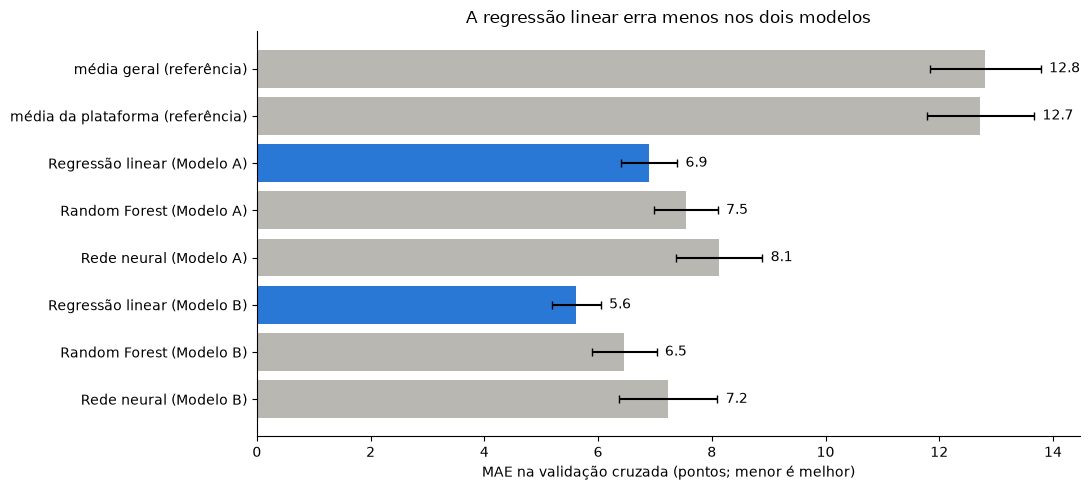

Modelo A: a Random Forest erra 9% e a rede neural 18% mais que a linear
Modelo B: a Random Forest erra 15% e a rede neural 29% mais que a linear


In [6]:
mae = pd.Series({chave: r["MAE"].mean() for chave, r in resultados.items()})
desvio = pd.Series({chave: r["MAE"].std() for chave, r in resultados.items()})
fig, ax = plt.subplots(figsize=(11, 5))
rotulos = [f"{modelo} ({conjunto})" for conjunto, modelo in mae.index]
cores = [AZUL if modelo == "Regressão linear" else CINZA_CLARO for _, modelo in mae.index]
barras = ax.barh(rotulos[::-1], mae.values[::-1], xerr=desvio.values[::-1], color=cores[::-1], capsize=3)
ax.bar_label(barras, labels=[f"{v:.1f}" for v in mae.values[::-1]], padding=6)
ax.set_xlabel("MAE na validação cruzada (pontos; menor é melhor)")
ax.set_title("A regressão linear erra menos nos dois modelos")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for conjunto in CONJUNTOS:
    linear = mae[(f"Modelo {conjunto}", "Regressão linear")]
    print(f"Modelo {conjunto}: a Random Forest erra {(mae[(f'Modelo {conjunto}', 'Random Forest')] / linear - 1) * 100:.0f}% "
          f"e a rede neural {(mae[(f'Modelo {conjunto}', 'Rede neural')] / linear - 1) * 100:.0f}% mais que a linear")

**Lendo a comparação:**

- **A regressão linear erra menos nos dois modelos:** 6,89 pontos no Modelo A (R² 0,70) e 5,62 no B (R² 0,79).
- **A Random Forest erra 9% mais no A** (7,54) **e 15% mais no B** (6,46). Os efeitos somam de forma simples, e com 400 criativos as árvores não acham combinações que compensem. Além disso, cada árvore aprende com só uma parte dos dados.
- **A rede neural é a pior, mesmo ajustada:** 8,13 no A (18% mais) e 7,24 no B (29% mais). O melhor tamanho foi uma camada de 64 neurônios; com duas camadas, piora (9,00). Mais flexibilidade não ajuda com 400 exemplos, e ela é uma caixa-preta que não dá efeitos em pontos.
- **Todos ganham das referências:** a linear corta o erro de quem chuta a média em 46% (de 12,8 para 6,9 pontos).

## Passo 6: um modelo para todas as redes ou um por rede?

A Parte 1 mostrou que o que funciona é quase igual nas três redes. Se for verdade, **um modelo só** (que já sabe a rede de cada criativo) deve errar menos que **três modelos separados**, porque cada modelo separado aprende com menos exemplos. Testo nas mesmas 15 provas: em cada uma, treino o modelo global e os três por rede, e meço o erro de cada rede na parte de validação.

In [7]:
colunas_por_rede = [c for c in COLUNAS_A if c != "platform"]
categorias_por_rede = [c for c in CATEGORIAS_A if c != "platform"]
linhas = []
for numero, (dentro, fora) in enumerate(cortes):
    parte_treino, parte_validacao = treino.iloc[dentro], treino.iloc[fora]
    global_ = pipeline(LinearRegression(), "A").fit(parte_treino[COLUNAS_A], parte_treino[ALVO])
    for rede in ["Meta", "TikTok", "LinkedIn"]:
        treino_rede = parte_treino[parte_treino["platform"] == rede]
        validacao_rede = parte_validacao[parte_validacao["platform"] == rede]
        separado = montar_pipeline(LinearRegression(), NUMERICAS, categorias_por_rede).fit(treino_rede[colunas_por_rede], treino_rede[ALVO])
        linhas.append({
            "rede": rede, "corte": numero, "criativos no treino": len(treino_rede),
            "MAE global": np.mean(np.abs(global_.predict(validacao_rede[COLUNAS_A]) - validacao_rede[ALVO])),
            "MAE por rede": np.mean(np.abs(separado.predict(validacao_rede[colunas_por_rede]) - validacao_rede[ALVO])),
        })
por_rede = pd.DataFrame(linhas)
por_rede["global ganha?"] = por_rede["MAE global"] < por_rede["MAE por rede"]
por_rede.groupby("rede", sort=False).agg(
    criativos_no_treino=("criativos no treino", "mean"), MAE_global=("MAE global", "mean"),
    MAE_por_rede=("MAE por rede", "mean"), cortes_em_que_o_global_ganha=("global ganha?", "sum")).round(2)

,criativos_no_treino,MAE_global,MAE_por_rede,cortes_em_que_o_global_ganha
rede,,,,
Meta,154.4,6.54,6.56,8
TikTok,112.8,6.92,7.15,8
LinkedIn,52.8,7.88,8.79,12


**Lendo a tabela:**

- **O modelo global ganha no TikTok** (6,92 contra 7,15) **e no LinkedIn** (7,88 contra 8,79, em 12 de 15 provas) **e empata no Meta** (6,54 contra 6,56).
- **Quem mais perde com o modelo separado é a rede com menos dados:** o LinkedIn tem só cerca de 53 criativos no treino de cada prova. O modelo global "empresta" o que aprendeu nas outras redes.
- **Confirma a Parte 1:** o que funciona é quase igual nas três redes, e a diferença do TikTok já está na coluna música/voz × TikTok.
- **Limite:** com tão poucos criativos no LinkedIn, não dá para afirmar diferenças finas dele; só que um modelo próprio, hoje, erraria mais.

## Passo 7: a escolha, e o modelo salvo

**Escolha: regressão linear, nos dois modelos.**

- **Erro:** é a que menos erra (passo 5).
- **Interpretação:** dá efeitos em pontos ("ter gancho vale +X pontos"), que a Parte 3 precisa. A Random Forest e a rede neural não dão.
- **Simplicidade:** não tem hiperparâmetro para ajustar, então não há risco de ter escolhido um ajuste que só funcionou nestas 15 provas.
- **Ponto de atenção:** duas colunas andam juntas (TikTok e música/voz × TikTok, notebook 2.1). Numa regressão linear, isso pode deixar os pesos dessas duas instáveis; o notebook 2.4 confere que eles se mantêm nas 15 provas.

Os dois modelos finais são treinados com **todo o treino** (as 400 linhas) e salvos com `joblib` (grava o Pipeline inteiro num arquivo, para a Parte 3 carregar e usar). Junto, salvo os efeitos do Modelo A **em pontos de nota** (`data/processed/efeitos_modelo_pontos.csv`): o peso de cada coluna, com a padronização desfeita (peso ÷ desvio da coluna). Para uma coluna 0/1, é "quantos pontos a mais por ter isso, mantendo o resto igual".

In [8]:
(RAIZ / "models").mkdir(exist_ok=True)
modelos_finais = {}
for conjunto, (colunas, _) in CONJUNTOS.items():
    modelos_finais[conjunto] = pipeline(LinearRegression(), conjunto).fit(treino[colunas], y)
    joblib.dump(modelos_finais[conjunto], RAIZ / f"models/modelo_{conjunto}.joblib")

efeitos = efeitos_em_pontos(modelos_finais["A"], treino[COLUNAS_A]).rename("efeito (pontos)")
efeitos.rename_axis("variável").reset_index().to_csv(RAIZ / "data/processed/efeitos_modelo_pontos.csv", index=False)
print("Salvos: models/modelo_A.joblib, models/modelo_B.joblib e data/processed/efeitos_modelo_pontos.csv")
efeitos.sort_values(key=abs, ascending=False).head(10).round(1).to_frame()

Salvos: models/modelo_A.joblib, models/modelo_B.joblib e data/processed/efeitos_modelo_pontos.csv


,efeito (pontos)
has_hook,17.9
text_density_high,-15.1
has_face,11.5
musica_x_tiktok,-11.5
has_subtitle_sim,8.1
text_density_low,-7.6
has_cta,7.5
platform_TikTok,6.4
objective_app_install,-5.5
objective_engagement,-4.8


Atenção às colunas numéricas: para a duração, o efeito é **por segundo**; para a música/voz (0 = só voz, 1 = só música), é de "só voz" para "só música". O notebook 2.4 lê todos os efeitos com calma.

## Resposta à pergunta 2.2: qual modelo treinei, e por quê?

> 💡 **Conclusão**
>
> - **Treinei três modelos de regressão** (regressão linear, Random Forest e rede neural), nos Modelos A e B, e **escolhi a regressão linear.**
> - **Por quê, em erro:** é a que menos erra. Antes de postar, ela erra em média 6,9 pontos, contra 12,8 de quem chuta a média (46% a menos). A Random Forest (7,5) e a rede neural (8,1), mesmo ajustadas, erram mais: com 400 criativos e efeitos que somam de forma simples, o modelo simples ganha.
> - **Por quê, em uso:** ela dá efeitos em pontos ("ter gancho vale +18 pontos"), que a Parte 3 precisa para recomendar mudanças, e não tem ajuste fino que possa ter funcionado só por sorte.
> - **Um modelo para as três redes é melhor que um por rede**, principalmente no LinkedIn, que tem poucos criativos. O Modelo A, o B e os efeitos em pontos estão salvos para a Parte 3.